In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Part 2


In [77]:
import pickle

In [78]:
df_log=pd.read_csv("penguins_preprocessed.csv")

In [79]:
print(df_log.shape)
print(df_log.head())

(344, 13)
   Unnamed: 0  calorie requirement  average sleep duration  bill_length_mm  \
0           0                 6563                      11       -0.929246   
1           1                 4890                      14       -0.854613   
2           2                 7184                      11       -0.705349   
3           3                 4169                       8        0.263789   
4           4                 4774                       8       -1.377038   

   bill_depth_mm  flipper_length_mm  body_mass_g  gender      year  \
0       0.776082          -1.428009    -0.568659       0 -1.270744   
1       0.103084          -1.068189    -0.505851       1 -1.270744   
2       0.413698          -0.420512    -1.196740       1 -1.270744   
3       0.423182          -0.221540    -0.191810       0 -1.270744   
4       1.086696          -0.564440    -0.945507       1 -1.270744   

   species_chinstrap  species_gentoo  island_dream  island_torgersen  
0              False         


Experiment 1 {'lr': 0.01, 'iters': 10000, 'seed': 1}
Iter 0, Loss=0.6931
Iter 1000, Loss=0.3960
Iter 2000, Loss=0.3462
Iter 3000, Loss=0.3266
Iter 4000, Loss=0.3165
Iter 5000, Loss=0.3105
Iter 6000, Loss=0.3066
Iter 7000, Loss=0.3040
Iter 8000, Loss=0.3020
Iter 9000, Loss=0.3006
Confusion Matrix:
 [[33  1]
 [ 4 31]]
Accuracy: 0.9275, Precision: 0.9687, Recall: 0.8857, F1: 0.9254

Experiment 2 {'lr': 0.001, 'iters': 20000, 'seed': 2}
Iter 0, Loss=0.6931
Iter 1000, Loss=0.6117
Iter 2000, Loss=0.5571
Iter 3000, Loss=0.5173
Iter 4000, Loss=0.4872
Iter 5000, Loss=0.4636
Iter 6000, Loss=0.4447
Iter 7000, Loss=0.4292
Iter 8000, Loss=0.4163
Iter 9000, Loss=0.4053
Iter 10000, Loss=0.3960
Iter 11000, Loss=0.3879
Iter 12000, Loss=0.3809
Iter 13000, Loss=0.3747
Iter 14000, Loss=0.3692
Iter 15000, Loss=0.3643
Iter 16000, Loss=0.3599
Iter 17000, Loss=0.3560
Iter 18000, Loss=0.3524
Iter 19000, Loss=0.3492
Confusion Matrix:
 [[32  2]
 [ 4 31]]
Accuracy: 0.9130, Precision: 0.9394, Recall: 0.8857, F1: 

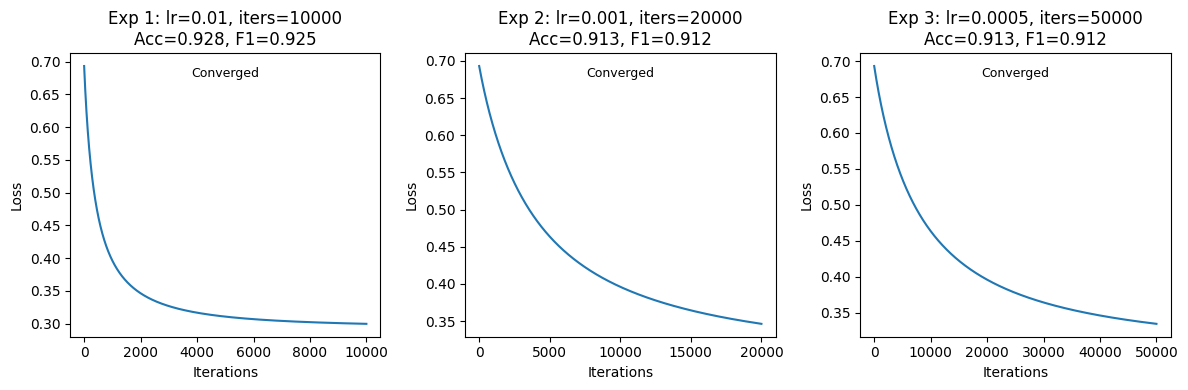


Best model saved with accuracy: 0.927536231884058


In [80]:
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def precision_recall_f1(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    precision = tp / (tp + fp + 1e-10)
    recall = tp / (tp + fn + 1e-10)
    f1 = (2 * precision * recall) / (precision + recall + 1e-10)
    return precision, recall, f1

def confusion_matrix_2x2(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def train_test_split(X, Y, test_size=0.2, seed=42):
    np.random.seed(seed)
    indices = np.arange(X.shape[0])
    np.random.shuffle(indices)
    split = int((1 - test_size) * X.shape[0])
    train_idx, test_idx = indices[:split], indices[split:]
    return X[train_idx], X[test_idx], Y[train_idx], Y[test_idx]

class LogitRegression:
    def __init__(self, lr=0.001, iters=10000, seed=42):
        np.random.seed(seed)
        self.lr = lr
        self.iters = iters
        self.W = None
        self.b = None
        self.loss_history = []
        self.mean = None
        self.std = None

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def _scale(self, X):
        return (X - self.mean) / (self.std + 1e-10)

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0)
        X = self._scale(X)
        self.W = np.zeros(n_features)
        self.b = 0

        for i in range(self.iters):
            linear = np.dot(X, self.W) + self.b
            y_pred = self.sigmoid(linear)

       
            loss = -np.mean(y * np.log(y_pred + 1e-10) +
                            (1 - y) * np.log(1 - y_pred + 1e-10))
            self.loss_history.append(loss)

            dw = np.dot(X.T, (y_pred - y)) / n_samples
            db = np.mean(y_pred - y)

            self.W -= self.lr * dw
            self.b -= self.lr * db

            if i % 1000 == 0:
                print(f"Iter {i}, Loss={loss:.4f}")

            if np.isnan(loss) or np.isinf(loss):
                print(f"Stopped at {i}, invalid loss")
                break

    def predict(self, X, threshold=0.5):
        X = self._scale(X)
        linear = np.dot(X, self.W) + self.b
        probs = self.sigmoid(linear)
        return (probs >= threshold).astype(int)

if __name__ == "__main__":
    df_log = pd.read_csv("penguins_preprocessed.csv")

    Y = df_log["gender"].astype(int).values
    X = df_log.drop(columns=["gender"]).values.astype(float)

    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, seed=42)

    experiments = [
        {"lr": 0.01, "iters": 10000, "seed": 1},
        {"lr": 0.001, "iters": 20000, "seed": 2},
        {"lr": 0.0005, "iters": 50000, "seed": 3},
    ]

    results = []
    best_model = None
    best_acc = -1

    for i, params in enumerate(experiments, 1):
        print(f"\nExperiment {i} {params}")
        model = LogitRegression(lr=params["lr"], iters=params["iters"], seed=params["seed"])
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec, rec, f1 = precision_recall_f1(y_test, y_pred)
        cm = confusion_matrix_2x2(y_test, y_pred)

        print("Confusion Matrix:\n", cm)
        print(f"Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}")

        results.append((params, acc, prec, rec, f1, model.loss_history))

        if acc > best_acc:
            best_acc = acc
            best_model = model

    plt.figure(figsize=(12, 4))
    for i, (params, acc, prec, rec, f1, loss_hist) in enumerate(results, 1):
        plt.subplot(1, 3, i)
        plt.plot(loss_hist)
        plt.title(f"Exp {i}: lr={params['lr']}, iters={params['iters']}\nAcc={acc:.3f}, F1={f1:.3f}")
        plt.xlabel("Iterations")
        plt.ylabel("Loss")
        # description under plot
        if loss_hist[-1] > loss_hist[0]:
            desc = "Diverged"
        elif abs(loss_hist[-1] - loss_hist[0]) < 1e-3:
            desc = "Plateau"
        else:
            desc = "Converged"
        plt.text(0.5, 0.95, desc, ha='center', va='top', transform=plt.gca().transAxes, fontsize=9)

    plt.tight_layout()
    plt.show()

    weights = {"W": best_model.W, "b": best_model.b,
               "mean": best_model.mean, "std": best_model.std}
    with open("a1_part_2_weights_odrabira_pranayla.pkl", "wb") as f:
        pickle.dump(weights, f)

    print("\nBest model saved with accuracy:", best_acc)



# Best Hyperparameters

The best results came from the setup with:
Learning rate = 0.01
Iterations = 10,000
Seed = 1

This combination worked best because the learning rate was high enough to let the model learn quickly, but not so high that it overshot the optimum. With fewer iterations the model hadn’t fully converged, while with a very small learning rate it took forever to improve. This balance gave us the highest accuracy and F1 score

# Issues We Faced

At first, the loss sometimes turned into NaN because of log(0). We fixed this by adding a very small constant (1e-10) inside the log.
The model kept getting stuck at 50% accuracy and predicting only one class. Standardizing the features solved this.
With a very small learning rate (like 0.0001), the model took forever to improve and basically plateaued. Using a slightly higher learning rate fixed this.
Overall, once we tuned the hyperparameters and added scaling, the model converged well and gave strong performance.

# References
https://pandas.pydata.org
https://numpy.org
https://elcaiseri.medium.com/building-a-simple-logistic-regression-model-from-scratch-with-numpy-c8cf2439d059
https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/


| Team Member | Assignment part | Contribution |
|----------|----------|----------|
| Odra Bira | Part 1  | 50% |
| Pranay Lachuluri | Part 2 | 50% |
| Odra Bira | Part 2  | 50% |
| Pranay Lachuluri | Part 1 | 50% |

